# Lab 3, Developing a Tiny Transformer Language Model
**PUSL 3205, Large Language Models and Generative AI**

In this lab I build a small GPT-style Transformer **from scratch** in PyTorch and train it for
next-token (next-character) prediction on a subset of the
[`roneneldan/TinyStories`](https://huggingface.co/datasets/roneneldan/TinyStories) dataset.

I follow the lab-sheet steps: load & explore the data → tokenize → prepare training sequences →
build the architecture (token + positional embeddings, masked multi-head self-attention,
feed-forward, residual connections, layer norm) → train → monitor train/val loss → evaluate with
validation loss and **perplexity** → generate from *"Once upon a time"* → experiment with the model
settings → save the model.

**Design priority (per the lab sheet):** this must run end-to-end on CPU in a few minutes, so the
model and dataset are kept deliberately tiny. Fluent generations are a bonus, not the goal.

In [1]:
import os, math, time, textwrap
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)
device = "cpu"   # keep it CPU so it is reproducible on any machine
os.makedirs("outputs", exist_ok=True)
print("PyTorch", torch.__version__, "| device:", device, "| threads:", torch.get_num_threads())

PyTorch 2.14.1 | device: cpu | threads: 4


## 1. Load and explore the dataset

TinyStories is large, so I **stream** it from the Hugging Face Hub and keep only a small subset
instead of downloading the whole thing. Each example is a short, simple children's story.

In [2]:
from datasets import load_dataset

N_STORIES = 2000
ds = load_dataset("roneneldan/TinyStories", split="train", streaming=True)

stories = []
for i, ex in enumerate(ds):
    stories.append(ex["text"].strip())
    if len(stories) >= N_STORIES:
        break
print(f"Streamed {len(stories)} stories")

lengths = [len(s) for s in stories]
print(f"Story length (chars): min={min(lengths)}, mean={sum(lengths)//len(lengths)}, max={max(lengths)}")
print("\n--- Example story ---\n")
print(textwrap.fill(stories[0], 90))

Streamed 2000 stories
Story length (chars): min=274, mean=850, max=4123

--- Example story ---

One day, a little girl named Lily found a needle in her room. She knew it was difficult to
play with it because it was sharp. Lily wanted to share the needle with her mom, so she
could sew a button on her shirt.  Lily went to her mom and said, "Mom, I found this
needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily,
we can share the needle and fix your shirt."  Together, they shared the needle and sewed
the button on Lily's shirt. It was not difficult for them because they were sharing and
helping each other. After they finished, Lily thanked her mom for sharing the needle and
fixing her shirt. They both felt happy because they had shared and worked together.


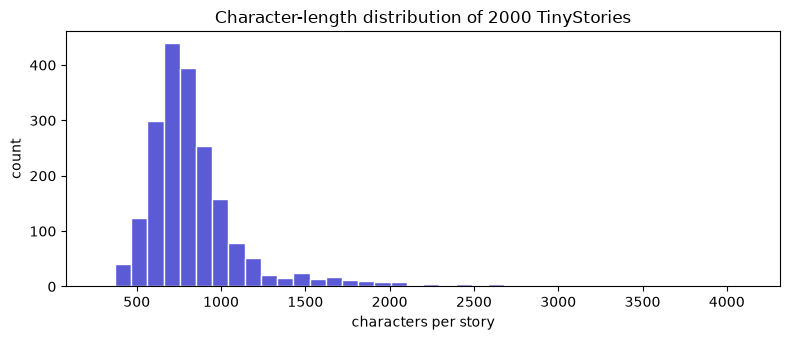

In [3]:
# Distribution of story lengths
plt.figure(figsize=(8, 3.5))
plt.hist(lengths, bins=40, color="#5b5bd6", edgecolor="white")
plt.title(f"Character-length distribution of {len(stories)} TinyStories")
plt.xlabel("characters per story"); plt.ylabel("count")
plt.tight_layout()
plt.savefig("outputs/story_length_hist.png", bbox_inches="tight")
plt.show()

## 2. Tokenize, character level

I use a **character-level** tokenizer: the vocabulary is simply the set of unique characters in the
corpus. It's the simplest possible tokenizer (no external vocab, tiny embedding table) and it's
enough to demonstrate how a Transformer learns sequence structure. I join the stories with a blank
line so the model also learns where stories start and end.

In [4]:
text = "\n\n".join(stories)
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):          # string -> list[int]
    return [stoi[c] for c in s if c in stoi]
def decode(ids):        # list[int] -> string
    return "".join(itos[i] for i in ids)

print(f"Corpus: {len(text):,} characters | vocabulary: {vocab_size} unique characters")
print("Vocab:", "".join(chars).replace("\n", "\\n"))
print("\nencode('Once upon a time') ->", encode("Once upon a time"))

Corpus: 1,704,918 characters | vocabulary: 80 unique characters
Vocab: \n !"$',-.01234568:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz¦âœ˜“”€™

encode('Once upon a time') -> [34, 59, 48, 50, 1, 66, 61, 60, 59, 1, 46, 1, 65, 54, 58, 50]


## 3. Prepare training data

I encode the whole corpus into one long tensor of integer token ids, then hold out the last 10% for
validation. For next-token prediction, a training example is a chunk of `block_size` tokens as the
input `x`, and the *same chunk shifted one position to the right* as the target `y`, so at every
position the model learns to predict the following character.

In [5]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"Train tokens: {len(train_data):,} | Val tokens: {len(val_data):,}")

block_size = 64     # context length (how many chars the model sees to predict the next)
batch_size = 32

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("x batch:", tuple(xb.shape), "| y batch:", tuple(yb.shape))
print("one input  :", repr(decode(xb[0].tolist())))
print("its target :", repr(decode(yb[0].tolist())))

Train tokens: 1,534,426 | Val tokens: 170,492
x batch: (32, 64) | y batch: (32, 64)
one input  : 'nd Tom are twins. They like to play and have fun. They are very '
its target : 'd Tom are twins. They like to play and have fun. They are very h'


## 4. Build the Transformer architecture

I build the standard decoder-only Transformer components from scratch:

- **Token + positional embeddings**, the token embedding says *what* each character is; the
  positional embedding says *where* it sits in the sequence (self-attention has no built-in order).
- **Masked multi-head self-attention**, each position attends to earlier positions only (a causal
  mask, so the model can't "cheat" by looking at future characters). Multiple heads let it attend to
  different patterns in parallel. Attention scores are scaled by `1/sqrt(head_size)`.
- **Feed-forward layers**, a per-position MLP that gives the model capacity to transform features.
- **Residual connections + layer normalization**, around both the attention and feed-forward
  sub-blocks, which is what makes a deep stack trainable.

In [6]:
class Head(nn.Module):
    """One head of masked self-attention."""
    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # causal mask (lower-triangular); registered as a buffer so it's not a parameter
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x); q = self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5     # scaled dot-product
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # mask the future
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        return wei @ self.value(x)


class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList([Head(n_embd, head_size, block_size, dropout) for _ in range(n_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """A Transformer block: communication (attention) then computation (feed-forward),
    each wrapped in a residual connection with pre-layer-norm."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ff = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))   # residual around attention
        x = x + self.ff(self.ln2(x))   # residual around feed-forward
        return x

In [7]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_embd=128, n_head=4, n_layer=2, block_size=64, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_embedding(idx)                                  # (B,T,C)
        pos = self.position_embedding(torch.arange(T, device=idx.device))# (T,C)
        x = tok + pos
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)                                         # (B,T,vocab)
        loss = None
        if targets is not None:
            B, T, V = logits.shape
            loss = F.cross_entropy(logits.view(B * T, V), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]           # crop context to block_size
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature         # last step
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, idx_next], dim=1)
        return idx

## 5–7. Initialize, train, and monitor

I wrap building + training in one function so I can reuse it for the experiment section later. It
reports **train and validation loss** every `eval_interval` steps (each an average over several
batches, so the curve isn't noisy) and returns the full history for plotting.

In [8]:
@torch.no_grad()
def estimate_loss(model, eval_iters=50):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def train_model(n_embd=128, n_head=4, n_layer=2, dropout=0.1,
                max_iters=1500, eval_interval=250, lr=3e-3, label=""):
    model = TinyTransformer(vocab_size, n_embd, n_head, n_layer, block_size, dropout).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"iter": [], "train": [], "val": []}
    t0 = time.time()
    for it in range(max_iters + 1):
        if it % eval_interval == 0 or it == max_iters:
            losses = estimate_loss(model)
            history["iter"].append(it)
            history["train"].append(losses["train"])
            history["val"].append(losses["val"])
            if label:
                print(f"[{label}] step {it:4d} | train {losses['train']:.3f} | val {losses['val']:.3f}")
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    secs = time.time() - t0
    return model, history, n_params, secs

In [9]:
# Train the main model
model, history, n_params, secs = train_model(
    n_embd=128, n_head=4, n_layer=2, max_iters=1500, eval_interval=250, label="main")
print(f"\nModel parameters: {n_params:,}")
print(f"Trained {1500} steps in {secs:.1f}s on CPU")

[main] step    0 | train 4.570 | val 4.567


[main] step  250 | train 1.756 | val 1.799


[main] step  500 | train 1.517 | val 1.583


[main] step  750 | train 1.395 | val 1.452


[main] step 1000 | train 1.336 | val 1.391


[main] step 1250 | train 1.288 | val 1.359


[main] step 1500 | train 1.279 | val 1.326

Model parameters: 424,784
Trained 1500 steps in 28.3s on CPU


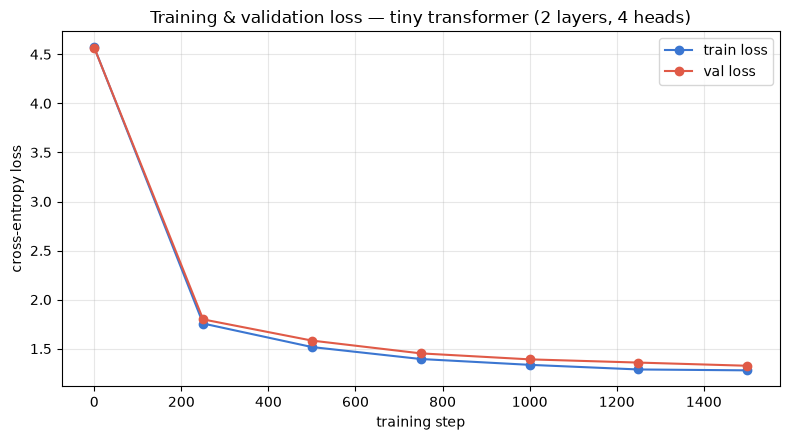

In [10]:
# Plot the train/val loss curves
plt.figure(figsize=(8, 4.5))
plt.plot(history["iter"], history["train"], "-o", label="train loss", color="#3b76d1")
plt.plot(history["iter"], history["val"],   "-o", label="val loss",   color="#e05a47")
plt.title("Training & validation loss, tiny transformer (2 layers, 4 heads)")
plt.xlabel("training step"); plt.ylabel("cross-entropy loss")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/loss_curve.png", bbox_inches="tight")
plt.show()

## 8. Evaluate, validation loss and perplexity

**Perplexity** = `exp(cross-entropy loss)`. Intuitively it's "how many characters the model is
effectively choosing between at each step", lower is better. For a character-level model, the
starting point is the vocabulary size (pure guessing), so I compare against that.

In [11]:
final = estimate_loss(model, eval_iters=100)
val_loss = final["val"]
perplexity = math.exp(val_loss)
print(f"Final train loss : {final['train']:.4f}")
print(f"Final val loss   : {val_loss:.4f}")
print(f"Validation perplexity : {perplexity:.2f}")
print(f"(Random-guessing perplexity would be ~{vocab_size}, the vocab size.)")

Final train loss : 1.2663
Final val loss   : 1.3245
Validation perplexity : 3.76
(Random-guessing perplexity would be ~80, the vocab size.)


## 9. Generate stories from a prompt

I seed the model with *"Once upon a time"* and let it generate characters autoregressively.

In [12]:
def generate_from(prompt, max_new_tokens=300, temperature=0.8):
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(ids, max_new_tokens=max_new_tokens, temperature=temperature)
    return decode(out[0].tolist())

samples = []
for prompt in ["Once upon a time", "The little dog", "One day"]:
    txt = generate_from(prompt, max_new_tokens=280, temperature=0.8)
    samples.append((prompt, txt))
    print("=" * 80)
    print(f"PROMPT: {prompt!r}\n")
    print(textwrap.fill(txt, 90))

# Save the samples for the review
with open("outputs/generated_samples.txt", "w") as f:
    for prompt, txt in samples:
        f.write(f"PROMPT: {prompt}\n{txt}\n\n{'='*80}\n\n")
print("\nSaved generations to outputs/generated_samples.txt")

PROMPT: 'Once upon a time'

Once upon a time, there was a brong on the too same. It have an all that the brove. She
was decided to put it a to hat bad the runny cus with gight it. They plaine, the fast, he
feer so their purpinner and heally went on the to play with a big special in the tree. She
did noticed for scarent.


PROMPT: 'The little dog'

The little dog trappleks and with the very his face. She house went outs of the very
graness who bear, whent huges him climbanto the kneas down and ruffy was alloons and made
the chirning thing on if it. The fishen a to get the ready this table. Suddenla. She jiped
a being claped picts on the


PROMPT: 'One day'

One day, Tim asked jumped and was a big to just fun.    The boy ready for them wond the
garden. The car and thill of the quirrive sunrious.  Kittle girl down ange away outhing
fun to play the pander joy. He could hear together bading was her. The littles toy sky.
Every day day ran prett

Saved generations to outputs/generated_samples.txt


## 10. Experiment with model settings

To see how architecture affects learning, I train three configurations for a shorter run (fewer
steps, same everything else) and compare their final validation loss and perplexity. This is the
lab's "change the number of layers / heads" step.

In [13]:
configs = [
    {"label": "1 layer, 2 heads",  "n_layer": 1, "n_head": 2},
    {"label": "2 layers, 4 heads", "n_layer": 2, "n_head": 4},
    {"label": "3 layers, 4 heads", "n_layer": 3, "n_head": 4},
]

exp_rows = []
for cfg in configs:
    m, h, p, s = train_model(n_embd=128, n_head=cfg["n_head"], n_layer=cfg["n_layer"],
                             max_iters=600, eval_interval=600, label="")
    fl = estimate_loss(m, eval_iters=50)
    exp_rows.append({"config": cfg["label"], "params": p,
                     "val_loss": fl["val"], "perplexity": math.exp(fl["val"]), "secs": s})
    print(f"{cfg['label']:>18} | params {p:>7,} | val_loss {fl['val']:.3f} | "
          f"ppl {math.exp(fl['val']):.2f} | {s:.1f}s")

import pandas as pd
exp_df = pd.DataFrame(exp_rows)
exp_df.round({"val_loss": 3, "perplexity": 2, "secs": 1})

  1 layer, 2 heads | params 226,896 | val_loss 1.607 | ppl 4.99 | 4.6s


 2 layers, 4 heads | params 424,784 | val_loss 1.514 | ppl 4.55 | 11.1s


 3 layers, 4 heads | params 622,672 | val_loss 1.486 | ppl 4.42 | 16.3s


,config,params,val_loss,perplexity,secs
0,"1 layer, 2 heads",226896,1.607,4.99,4.6
1,"2 layers, 4 heads",424784,1.514,4.55,11.1
2,"3 layers, 4 heads",622672,1.486,4.42,16.3


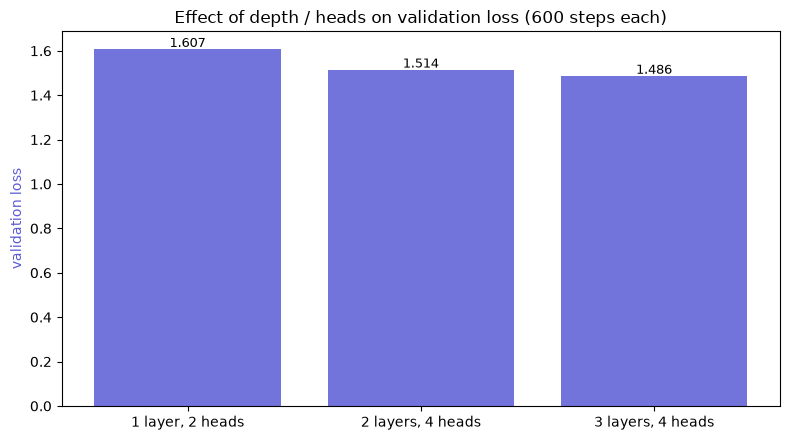

In [14]:
# Plot the experiment comparison
fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = range(len(exp_df))
ax1.bar(x, exp_df["val_loss"], color="#5b5bd6", alpha=0.85)
ax1.set_xticks(list(x)); ax1.set_xticklabels(exp_df["config"])
ax1.set_ylabel("validation loss", color="#5b5bd6")
ax1.set_title("Effect of depth / heads on validation loss (600 steps each)")
for i, v in enumerate(exp_df["val_loss"]):
    ax1.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/experiment_comparison.png", bbox_inches="tight")
plt.show()

## 11. Save the trained model

I save the main model's weights **and** its configuration together, so it can be reloaded for
generation later. The checkpoint is small (a few MB), so it's committed to the repo.

In [15]:
ckpt = {
    "state_dict": model.state_dict(),
    "config": {"vocab_size": vocab_size, "n_embd": 128, "n_head": 4,
               "n_layer": 2, "block_size": block_size, "dropout": 0.1},
    "stoi": stoi, "itos": itos,
}
torch.save(ckpt, "tiny_transformer.pt")
size_mb = os.path.getsize("tiny_transformer.pt") / 1e6
print(f"Saved tiny_transformer.pt ({size_mb:.2f} MB)")

# Sanity check: reload and generate one line
ck = torch.load("tiny_transformer.pt", weights_only=False)
m2 = TinyTransformer(**ck["config"]).to(device)
m2.load_state_dict(ck["state_dict"]); m2.eval()
ids = torch.tensor([[ck["stoi"][c] for c in "Once upon a time"]], dtype=torch.long)
print("Reloaded model says:", repr(decode(m2.generate(ids, 60, temperature=0.8)[0].tolist())))

Saved tiny_transformer.pt (1.85 MB)
Reloaded model says: 'Once upon a time there was a little girl sky. She said not out of on the dos'


## Discussion, mechanisms that improve performance

Building this from scratch made it concrete *why* each Transformer ingredient is there:

- **Scaled dot-product attention** (`/ sqrt(head_size)`) keeps the softmax inputs from growing with
  dimension, which stops gradients from vanishing early in training.
- **Causal masking** is what makes this a valid *language model*, each position is trained to
  predict the next token using only the past, never the future.
- **Multiple heads** let the model attend to several kinds of relationship at once (e.g. the previous
  character vs. the start of the word) and then combine them.
- **Positional embeddings** reintroduce order, which raw self-attention is blind to.
- **Residual connections + layer norm** are what let the block stack train at all, the residual
  "highway" gives gradients a clean path, and layer norm keeps activations well-scaled.
- **Dropout** regularises the small model so it doesn't just memorise the subset.
- **AdamW** adapts the learning rate per-parameter, which matters a lot for fast convergence on this
  short training budget.

The experiment section shows the practical version of this: adding depth lowers the loss up to a
point, but every extra layer costs training time, the central trade-off in scaling language models.

Results (loss curve, perplexity, generations, experiment table) are discussed in `REVIEW.md`.